# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿se pueden convertir titulares de un diario peruano en un clasificador de noticias?

Este notebook parte de `datos/noticias.csv` (Parte 1: 376 noticias de El Comercio). La etiqueta de referencia (`etiqueta`) es la sección del diario mapeada a las 4 categorías oficiales. Sobre ella se comparan tres enfoques:

| Paso | Enfoque | Modelo |
| :--- | :--- | :--- |
| 1 | Línea base zero-shot (sin entrenamiento) | `Recognai/bert-base-spanish-wwm-cased-xnli` |
| 2 | Supervisión débil con LLM local | `Qwen2.5-1.5B-Instruct` (GGUF 4 bits, `llama.cpp`) |
| 3–5 | Transformer con fine-tuning | `distilbert/distilbert-base-multilingual-cased` |
| 6 | Comparativa y decisión | — |

**Equipo usado:** laptop con Windows, **solo CPU** (AMD Ryzen 5 5500U, 6 núcleos) y **7.3 GB de RAM**. Esta restricción explica varias decisiones técnicas, que se documentan en cada sección: el formato del LLM, el modelo zero-shot en español en lugar de `xlm-roberta-large` (2.2 GB) y los embeddings congelados en el fine-tuning.

In [1]:
import gc
import json
import shutil
import time
import warnings
from datetime import date
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

import truststore

# Valida HTTPS con los certificados del sistema (el antivirus intercepta HTTPS con su propio
# certificado raíz); lo necesita huggingface_hub para consultar los modelos.
truststore.inject_into_ssl()

import datasets
import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
import transformers
from datasets import Dataset
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, pipeline, set_seed)

# Salida limpia: sin barras de progreso de carga y guardado. También se silencia un aviso de
# transformers 5 sobre un "regex incorrecto" en el tokenizador, que es un falso positivo para
# DistilBERT (usa BertPreTokenizer + WordPiece).
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
huggingface_hub.utils.logging.set_verbosity_error()  # sin el aviso de "requests sin HF_TOKEN"

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 950
pio.templates.default = "plotly_white"
pd.set_option("display.max_colwidth", 110)

SEMILLA = 42
set_seed(SEMILLA)
DATOS, RAW, MODELO = Path("datos"), Path("datos/raw"), Path("modelo")
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

df = pd.read_csv(DATOS / "noticias.csv").fillna({"bajada": ""})
print("Fecha de ejecución:", date.today().isoformat(), "| df.shape:", df.shape)
df["etiqueta"].value_counts().reindex(ETIQUETAS).rename("noticias")

Fecha de ejecución: 2026-10-18 | df.shape: (376, 7)


etiqueta
politica              92
economia              90
deportes              98
ciencia_tecnologia    96
Name: noticias, dtype: int64

In [2]:
def metricas(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, labels=ETIQUETAS, average="macro", zero_division=0),
    }

## 1. Línea base zero-shot (sin fine-tuning)

Se evalúan **40 titulares** (10 por categoría, muestreo estratificado con `random_state=42`) con `pipeline("zero-shot-classification")` y el modelo NLI en español `Recognai/bert-base-spanish-wwm-cased-xnli`. Se eligió esta opción del enunciado en lugar de `joeddav/xlm-roberta-large-xnli`, que pesa 2.2 GB y no cabe con holgura en la RAM disponible.

El modelo no conoce las categorías. Para cada titular evalúa si se cumple la hipótesis *"Esta noticia trata sobre {categoría}."*. Se usan los nombres naturales en español (`política`, `economía`, `deportes`, `ciencia y tecnología`) y luego se mapean a las etiquetas oficiales. El F1 macro que se obtiene es el **piso mínimo** que deben superar los otros enfoques.

In [3]:
ZS_MODELO = "Recognai/bert-base-spanish-wwm-cased-xnli"
ZS_ETIQUETAS = {"política": "politica", "economía": "economia",
                "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}
zs = pipeline("zero-shot-classification", model=ZS_MODELO, device=-1)


def zero_shot(titulares):
    salida = zs(list(titulares), candidate_labels=list(ZS_ETIQUETAS),
                hypothesis_template="Esta noticia trata sobre {}.")
    return [ZS_ETIQUETAS[s["labels"][0]] for s in salida]


muestra_zs = df.groupby("etiqueta", group_keys=False).sample(n=10, random_state=SEMILLA).copy()
t0 = time.time()
muestra_zs["pred_zs"] = zero_shot(muestra_zs["titular"])
lat_zs40 = (time.time() - t0) / len(muestra_zs)
m_zs40 = metricas(muestra_zs["etiqueta"], muestra_zs["pred_zs"])
print(f"Zero-shot en 40 titulares -> accuracy {m_zs40['accuracy']:.3f} | F1 macro {m_zs40['f1_macro']:.3f} "
      f"| {lat_zs40 * 1000:.0f} ms por titular")
pd.crosstab(muestra_zs["etiqueta"], muestra_zs["pred_zs"], rownames=["real"], colnames=["zero-shot"])

Zero-shot en 40 titulares -> accuracy 0.650 | F1 macro 0.634 | 337 ms por titular


zero-shot,ciencia_tecnologia,deportes,economia,politica
real,,,,
ciencia_tecnologia,6,2,1,1
deportes,0,8,0,2
economia,1,1,3,5
politica,0,0,1,9


In [4]:
# Se libera memoria: el modelo zero-shot se vuelve a cargar en la comparativa final
del zs
gc.collect();

## 2. Supervisión débil con un LLM local

**Modelo:** `Qwen2.5-1.5B-Instruct`, en la versión GGUF oficial de Qwen cuantizada a 4 bits (`Q4_K_M`, ~1.1 GB), ejecutada con `llama.cpp` (`llama-cpp-python`). Se descartó la versión de `transformers` porque en `float32` necesita ~6 GB de RAM, casi toda la memoria del equipo. La versión de 4 bits cabe con holgura y corre a una velocidad razonable en CPU.

**Prompt estructurado** (formato de chat ChatML de Qwen):

- **Sistema:** define las 4 categorías con ejemplos de temas y pide responder solo con el nombre de la categoría.
- **6 ejemplos *few-shot* inventados:** no salen del dataset, para no filtrar información de test. Muestran el formato titular + bajada → categoría.
- **Usuario:** el titular y la bajada de la noticia que se clasifica.

**Etiqueta y confianza:** en lugar de generar texto libre, se calcula la probabilidad que el LLM asigna a cada respuesta posible:

- Se suman las variantes de escritura de cada categoría (con y sin tilde o mayúscula, por ejemplo `política` y `Política`).
- Se normaliza entre las 4 categorías.
- `etiqueta_llm` es la categoría de mayor probabilidad, así que el LLM no puede inventar una quinta categoría.
- `confianza` es esa probabilidad normalizada.

Cada respuesta se respalda en `datos/raw/llm_respuestas.jsonl`, así que al reejecutar el notebook no se recalcula lo ya etiquetado. En `etiquetas_llm.csv`, la columna `fecha` es la fecha del etiquetado.

In [5]:
LLM_REPO, LLM_ARCHIVO = "Qwen/Qwen2.5-1.5B-Instruct-GGUF", "qwen2.5-1.5b-instruct-q4_k_m.gguf"
MODELO_LLM = "Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M"

SISTEMA = """Eres editor de un diario peruano. Clasifica cada noticia en una de estas 4 categorías:
- política: gobierno, Congreso, Senado, elecciones, partidos, ministros, fiscalía y justicia sobre autoridades.
- economía: dólar, mercados, empresas, inversión, empleo, impuestos, precios, bancos, comercio.
- deportes: fútbol, clubes, partidos, goles, vóley, tenis, automovilismo, atletas y competencias.
- ciencia y tecnología: tecnología, empresas tecnológicas, internet, inteligencia artificial, celulares, videojuegos, salud y medicina, ciencia, espacio, animales, medio ambiente.
Responde solo con el nombre de la categoría."""

RESPUESTA = {"politica": "política", "economia": "economía", "deportes": "deportes",
             "ciencia_tecnologia": "ciencia y tecnología"}
VARIANTES = {
    "politica": ["política", "Política", "politica", "Politica"],
    "economia": ["economía", "Economía", "economia", "Economia"],
    "deportes": ["deportes", "Deportes"],
    "ciencia_tecnologia": ["ciencia y tecnología", "Ciencia y tecnología", "Ciencia y Tecnología",
                           "tecnología", "Tecnología"],
}
# Ejemplos few-shot inventados (no pertenecen al dataset)
EJEMPLOS = [
    ("Premier se presenta ante el pleno para pedir el voto de confianza",
     "El gabinete expuso su plan de gobierno ante el Congreso.", "politica"),
    ("Selección peruana convoca a tres juveniles para la fecha FIFA",
     "El técnico anunció la lista de convocados para los amistosos.", "deportes"),
    ("Apple presenta un nuevo chip para sus computadoras con IA",
     "La compañía promete el doble de velocidad y mejor batería.", "ciencia_tecnologia"),
    ("BCRP mantiene su tasa de referencia en 4.25%", "La inflación se ubicó dentro del rango meta.", "economia"),
    ("Científicos descubren una nueva especie de rana en la Amazonía",
     "El hallazgo fue publicado en una revista internacional.", "ciencia_tecnologia"),
    ("Alianza Lima empató 1-1 con Melgar en Matute",
     "Los íntimos no pudieron sostener la ventaja en el Torneo Clausura.", "deportes"),
]


def turno_usuario(titular, bajada):
    return f"<|im_start|>user\nTitular: {titular}\nBajada: {bajada}<|im_end|>\n<|im_start|>assistant\n"


# Plantilla de chat ChatML de Qwen: sistema + ejemplos few-shot (prefijo común a todas las noticias)
PREFIJO = f"<|im_start|>system\n{SISTEMA}<|im_end|>\n" + "".join(
    turno_usuario(t, b) + f"{RESPUESTA[e]}<|im_end|>\n" for t, b, e in EJEMPLOS)
print(PREFIJO + turno_usuario("<titular de la noticia>", "<bajada de la noticia>"))

<|im_start|>system
Eres editor de un diario peruano. Clasifica cada noticia en una de estas 4 categorías:
- política: gobierno, Congreso, Senado, elecciones, partidos, ministros, fiscalía y justicia sobre autoridades.
- economía: dólar, mercados, empresas, inversión, empleo, impuestos, precios, bancos, comercio.
- deportes: fútbol, clubes, partidos, goles, vóley, tenis, automovilismo, atletas y competencias.
- ciencia y tecnología: tecnología, empresas tecnológicas, internet, inteligencia artificial, celulares, videojuegos, salud y medicina, ciencia, espacio, animales, medio ambiente.
Responde solo con el nombre de la categoría.<|im_end|>
<|im_start|>user
Titular: Premier se presenta ante el pleno para pedir el voto de confianza
Bajada: El gabinete expuso su plan de gobierno ante el Congreso.<|im_end|>
<|im_start|>assistant
política<|im_end|>
<|im_start|>user
Titular: Selección peruana convoca a tres juveniles para la fecha FIFA
Bajada: El técnico anunció la lista de convocados para lo

In [6]:
llm = Llama(model_path=hf_hub_download(LLM_REPO, LLM_ARCHIVO), n_ctx=2048, n_threads=6,
            seed=SEMILLA, verbose=False)
tokens = lambda texto, especial: llm.tokenize(texto.encode("utf-8"), add_bos=False, special=especial)
SECUENCIAS = {e: [tokens(v, False) for v in vs] for e, vs in VARIANTES.items()}


def ultimos_logits():
    return np.ctypeslib.as_array(llm._ctx.get_logits(), shape=(llm.n_vocab(),)).astype(np.float64)


def log_softmax(v):
    m = v.max()
    return v - (m + np.log(np.exp(v - m).sum()))


# El prefijo (sistema + few-shot) se procesa una sola vez. Para cada noticia se "rebobina" la caché KV
# hasta el final del prefijo: eval() descarta todo lo posterior a llm.n_tokens.
llm.reset()
llm.eval(tokens(PREFIJO, True))
N_PREFIJO = llm.n_tokens


def clasificar_llm(titular, bajada):
    llm.n_tokens = N_PREFIJO
    llm.eval(tokens(turno_usuario(titular, bajada), True))
    n_noticia = llm.n_tokens
    lp_inicial = log_softmax(ultimos_logits())
    prob = {}
    for etiqueta, variantes in SECUENCIAS.items():
        total = 0.0
        for seq in variantes:            # P(respuesta completa | prompt), token a token
            lp = lp_inicial[seq[0]]
            if len(seq) > 1:
                llm.n_tokens = n_noticia
                for i in range(1, len(seq)):
                    llm.eval([seq[i - 1]])
                    lp += log_softmax(ultimos_logits())[seq[i]]
            total += np.exp(lp)
        prob[etiqueta] = total
    p = pd.Series(prob) / sum(prob.values())
    return p.idxmax(), float(p.max())


print(clasificar_llm("Congreso aprueba nuevo retiro de fondos de AFP",
                     "La medida beneficiará a más de 4 millones de afiliados."))

llama_new_context_with_model: n_ctx_per_seq (2048) < n_ctx_train (32768) -- the full capacity of the model will not be utilized


('politica', 0.8419195425190302)


In [7]:
RESPALDO_LLM = RAW / "llm_respuestas.jsonl"
hechas = {}
if RESPALDO_LLM.exists():
    for linea in RESPALDO_LLM.read_text(encoding="utf-8").splitlines():
        d = json.loads(linea)
        hechas[d["url"]] = d

pendientes = df[~df["url"].isin(hechas)]
print(f"Ya etiquetadas: {len(hechas)} | por etiquetar: {len(pendientes)}")
t0 = time.time()
with RESPALDO_LLM.open("a", encoding="utf-8") as f:
    for i, fila in enumerate(pendientes.itertuples(), 1):
        etiqueta, confianza = clasificar_llm(fila.titular, fila.bajada)
        d = {"url": fila.url, "etiqueta_llm": etiqueta, "confianza": round(confianza, 4),
             "fecha": date.today().isoformat()}
        f.write(json.dumps(d, ensure_ascii=False) + "\n")
        f.flush()
        hechas[fila.url] = d
        if i % 50 == 0:
            print(f"  {i}/{len(pendientes)} ({time.time() - t0:.0f} s)")
if len(pendientes):
    lat_llm = (time.time() - t0) / len(pendientes)
    (RAW / "llm_latencia.json").write_text(json.dumps({"segundos_por_noticia": lat_llm}), encoding="utf-8")
lat_llm = json.loads((RAW / "llm_latencia.json").read_text(encoding="utf-8"))["segundos_por_noticia"]
print(f"Latencia del LLM: {lat_llm:.2f} s por noticia en CPU")

del llm
gc.collect();

Ya etiquetadas: 376 | por etiquetar: 0
Latencia del LLM: 2.81 s por noticia en CPU


In [8]:
etiquetas_llm = df[["url", "titular"]].assign(
    etiqueta_llm=df["url"].map(lambda u: hechas[u]["etiqueta_llm"]),
    confianza=df["url"].map(lambda u: hechas[u]["confianza"]),
    modelo_llm=MODELO_LLM,
    fecha=df["url"].map(lambda u: hechas[u]["fecha"]),
)
etiquetas_llm = etiquetas_llm[["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha", "url"]]
etiquetas_llm.to_csv(DATOS / "etiquetas_llm.csv", index=False, encoding="utf-8")
print("Guardado datos/etiquetas_llm.csv", etiquetas_llm.shape)
etiquetas_llm.head()

Guardado datos/etiquetas_llm.csv (376, 6)


,titular,etiqueta_llm,confianza,modelo_llm,fecha,url
0,YouTube planea incorporar audiolibros en 2027 y ya estaría en conversación con editoriales,ciencia_tecnologia,0.9957,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/redes-sociales/youtube-planea-incorporar-audiolibros-en-2027-y-ya-estaria...
1,Fenómeno El Niño Costero: ¿cuáles pueden ser las consecuencias para el Perú?,ciencia_tecnologia,0.9996,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/actualidad/fenomeno-el-nino-costero-cuales-pueden-ser-las-consecuencias-p...
2,Videojuego peruano “Dark Rally” abre concurso para convertirte en uno de sus personajes,deportes,0.8724,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/videojuegos/videojuego-peruano-dark-rally-abre-concurso-para-convertirte-...
3,Tesla presenta un Roadster capaz de ‘volar’ y en las redes sociales lo reciben con memes,ciencia_tecnologia,0.9838,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/actualidad/tesla-presenta-un-roadster-capaz-de-volar-y-en-las-redes-socia...
4,Alemania investiga una presunta agresión sexual con un robot contra joven de 16 años,politica,0.8547,Qwen2.5-1.5B-Instruct-GGUF-Q4_K_M,2026-10-18,https://elcomercio.pe/tecnologia/robotica/alemania-investiga-una-presunta-agresion-sexual-con-un-robot-con...


### 2.1 ¿Cuánto coincide el LLM con la sección del diario?

In [9]:
df["etiqueta_llm"] = etiquetas_llm["etiqueta_llm"].values
df["confianza_llm"] = etiquetas_llm["confianza"].values
m_llm_total = metricas(df["etiqueta"], df["etiqueta_llm"])
print(f"LLM vs. sección (dataset completo, {len(df)} noticias) -> accuracy {m_llm_total['accuracy']:.3f} "
      f"| F1 macro {m_llm_total['f1_macro']:.3f}")

alta = df["confianza_llm"] >= 0.9
print(f"Con confianza >= 0.90 ({alta.mean():.0%} de las noticias): accuracy "
      f"{(df.loc[alta, 'etiqueta'] == df.loc[alta, 'etiqueta_llm']).mean():.3f}; con confianza < 0.90: "
      f"{(df.loc[~alta, 'etiqueta'] == df.loc[~alta, 'etiqueta_llm']).mean():.3f}")
pd.crosstab(df["etiqueta"], df["etiqueta_llm"], rownames=["sección"], colnames=["LLM"])

LLM vs. sección (dataset completo, 376 noticias) -> accuracy 0.880 | F1 macro 0.875
Con confianza >= 0.90 (79% de las noticias): accuracy 0.943; con confianza < 0.90: 0.650


LLM,ciencia_tecnologia,deportes,economia,politica
sección,,,,
ciencia_tecnologia,85,2,2,7
deportes,1,94,0,3
economia,19,1,60,10
politica,0,0,0,92


### 2.2 Auditoría humana de 20 predicciones al azar

Se toman 20 noticias al azar (`df.sample(n=20, random_state=42)`). La revisión se hace **a ciegas**: la estudiante clasifica cada noticia solo con el titular y la bajada, sin ver la etiqueta del LLM ni la sección del diario. Así su criterio no se ve influido por la respuesta del modelo.

Las etiquetas humanas se guardan en `datos/auditoria_humana.csv` (columna `etiqueta_humana`) y aquí se cruzan con las del LLM. El acuerdo es la proporción de casos en que ambas coinciden.

In [10]:
AUDITORIA = DATOS / "auditoria_humana.csv"
if not AUDITORIA.exists():
    # Plantilla para la revisión manual a ciegas: no incluye la etiqueta del LLM ni la sección
    (df.sample(n=20, random_state=SEMILLA)[["url", "titular", "bajada"]]
       .assign(etiqueta_humana="", comentario="")
       .to_csv(AUDITORIA, index=False, encoding="utf-8"))
aud = (pd.read_csv(AUDITORIA).fillna("")
         .merge(df[["url", "etiqueta_llm", "confianza_llm", "etiqueta"]], on="url", how="left"))
aud["etiqueta_humana"] = aud["etiqueta_humana"].str.strip().str.lower()
assert aud["etiqueta_humana"].isin(ETIQUETAS + [""]).all(), "Hay etiquetas humanas fuera de las 4 oficiales"

if (aud["etiqueta_humana"] != "").all():
    aud["coincide"] = aud["etiqueta_humana"] == aud["etiqueta_llm"]
    acuerdo = int(aud["coincide"].sum())
    print(f"Acuerdo LLM-humano: {acuerdo}/20 = {acuerdo / 20:.0%}")
    print(f"(Como referencia, humano vs. sección del diario: {(aud['etiqueta_humana'] == aud['etiqueta']).sum()}/20)")
else:
    acuerdo = None
    print("Auditoría pendiente: completar la columna etiqueta_humana en", AUDITORIA)
aud[["titular", "etiqueta_humana", "etiqueta_llm", "confianza_llm"] + (["coincide"] if acuerdo is not None else [])]

Acuerdo LLM-humano: 18/20 = 90%
(Como referencia, humano vs. sección del diario: 18/20)


,titular,etiqueta_humana,etiqueta_llm,confianza_llm,coincide
0,Renovación Popular se declara en reorganización partidaria: ¿A qué se debe y cuáles son los alcances de la...,politica,politica,0.9999,True
1,Senado: Comisión de Constitución suspende sesión sobre delegación de facultades,politica,politica,0.9979,True
2,Gobierno designa presidenta del directorio y directora ejecutiva del Fonafe,politica,politica,0.9945,True
3,Fabián Bustos previo al duelo ante Alianza Atlético: “El equipo va a seguir creciendo”,deportes,deportes,0.7413,True
4,¡Con doblete de Lionel Messi! Inter Miami derrotó 3-1 a Atlanta United por MLS | RESUMEN Y GOLES,deportes,deportes,0.9993,True
5,Francis Halzen gana el Nobel de Física por descubrir neutrinos de origen cósmico,ciencia_tecnologia,ciencia_tecnologia,1.0000,True
6,Eduardo Castro gana Caminos del Inca 2026 tras espectacular final en la sexta etapa entre Puno y Arequipa,deportes,deportes,0.9923,True
7,¿Por qué un gran danés vive menos que un chihuahua? La respuesta podría estar en su ADN,ciencia_tecnologia,ciencia_tecnologia,1.0000,True
8,Un Motorola razr 70 diferente: así es el teléfono de lujo con 34 cristales Swarovski Silver Night,ciencia_tecnologia,ciencia_tecnologia,0.9942,True
9,Ministro César Astudillo tras incidente en la Comisión de Constitución del Senado: “De mi parte esto ya ha...,politica,politica,0.9992,True


**Resultado:** acuerdo LLM–humano de **18/20 = 90 %**. Ese porcentaje es igual al acuerdo de la estudiante con la sección del diario (18/20), así que el LLM está tan cerca del criterio humano como la propia sección.

Los dos desacuerdos son casos frontera:

- **Infracon Perú 2026** (un evento de infraestructura e inversión): el LLM lo envió a `ciencia_tecnologia` y la estudiante y la sección a `economia`. Es un error del LLM, y fue de los pocos con confianza baja (0.75): la confianza sí avisa de sus dudas.
- **Visita de Rodrigo Paz para concretar acuerdos comerciales:** la estudiante lo leyó como `economia` por los acuerdos comerciales. El LLM y la sección (`politica/internacional`) lo vieron como política, porque es una visita presidencial.

El otro desacuerdo de la estudiante con la sección es la designación de la presidenta de **Fonafe**, que el diario publica en economía, aunque es un nombramiento del Gobierno. Estos casos muestran que una parte de los "errores" no son fallas del modelo, sino ambigüedad real entre política y economía.

## 3. Partición 70 / 15 / 15

Split estratificado por `etiqueta` con `random_state=42`, en dos pasos: primero 70 % train y 30 % temporal, y luego el temporal se divide en mitades para validación y test.

El conjunto de **test** no se usa para entrenar ni para elegir la mejor época. Solo se usa una vez, en la evaluación final (sección 5). La asignación de cada noticia se guarda en `datos/particion.csv`.

In [11]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEMILLA)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["etiqueta"], random_state=SEMILLA)

assert not (set(train_df["url"]) & set(val_df["url"]) or set(train_df["url"]) & set(test_df["url"])
            or set(val_df["url"]) & set(test_df["url"]))
pd.concat([train_df.assign(particion="train"), val_df.assign(particion="val"), test_df.assign(particion="test")]
          )[["url", "particion"]].to_csv(DATOS / "particion.csv", index=False)

resumen = pd.DataFrame({n: d["etiqueta"].value_counts() for n, d in
                        [("train", train_df), ("val", val_df), ("test", test_df)]}).reindex(ETIQUETAS)
resumen.loc["total"] = resumen.sum()
for nombre, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nombre:<5}: {len(d):>3} noticias ({len(d) / len(df):.1%})")
resumen

train: 263 noticias (69.9%)
val  :  56 noticias (14.9%)
test :  57 noticias (15.2%)


,train,val,test
etiqueta,,,
politica,64,14,14
economia,63,14,13
deportes,69,14,15
ciencia_tecnologia,67,14,15
total,263,56,57


## 4. Fine-tuning de DistilBERT multilingüe

- **Modelo:** `distilbert/distilbert-base-multilingual-cased`, el recomendado por el enunciado para CPU.
- **Entrada:** solo el `titular`, que es lo que recibirá el dashboard.
- **Configuración con `Trainer`:** 3 épocas, batch de 16, learning rate 5e-5, evaluación y guardado por época, y `metric_for_best_model="f1_macro"` (calculado con `sklearn.metrics.f1_score(average="macro")`). Al terminar se carga la mejor época según validación.
- **Ajuste por la RAM disponible:** se congela la matriz de embeddings de palabras, que tiene 92 M de los 135 M de parámetros. Así se entrena el resto del transformer y la capa de clasificación con bastante menos memoria. Con solo ~260 titulares de entrenamiento, esto además reduce el riesgo de sobreajuste.

Se entrenan dos versiones con la misma configuración y la misma partición:

1. **Modelo principal:** se entrena con la etiqueta de sección (`etiqueta`) y se guarda en `modelo/`.
2. **Variante de supervisión débil** (sección 6): se entrena solo con las etiquetas del LLM (`etiqueta_llm`). Sirve para medir cuánto se pierde si no se tuviera la sección del diario.

Los checkpoints intermedios se guardan en `modelo/checkpoint-trainer/` (excluido por `.gitignore`) y se borran al terminar.

In [12]:
BASE = "distilbert/distilbert-base-multilingual-cased"
EPOCAS = 3
id2label = dict(enumerate(ETIQUETAS))
label2id = {v: k for k, v in id2label.items()}
tok = AutoTokenizer.from_pretrained(BASE)


def a_dataset(d, columna="etiqueta"):
    ds = Dataset.from_dict({"text": d["titular"].tolist(), "label": d[columna].map(label2id).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)


def calcular_metricas(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}


def entrenar(columna, carpeta):
    set_seed(SEMILLA)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        BASE, num_labels=len(ETIQUETAS), id2label=id2label, label2id=label2id)
    modelo.distilbert.embeddings.word_embeddings.weight.requires_grad_(False)
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"Parámetros entrenables: {entrenables / 1e6:.0f} M de {modelo.num_parameters() / 1e6:.0f} M")
    args = TrainingArguments(
        output_dir=carpeta, num_train_epochs=EPOCAS, learning_rate=5e-5, weight_decay=0.01,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
        save_total_limit=1, save_only_model=True, seed=SEMILLA, use_cpu=True, report_to="none",
    )
    trainer = Trainer(model=modelo, args=args, processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                      train_dataset=a_dataset(train_df, columna), eval_dataset=a_dataset(val_df, columna),
                      compute_metrics=calcular_metricas)
    t0 = time.time()
    trainer.train()
    print(f"Entrenamiento: {time.time() - t0:.0f} s")
    shutil.rmtree(carpeta, ignore_errors=True)  # el mejor modelo ya está cargado en memoria
    return trainer

In [13]:
trainer = entrenar("etiqueta", str(MODELO / "checkpoint-trainer"))
historial = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
historial[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(4)

Parámetros entrenables: 44 M de 135 M


{'loss': '1.214', 'grad_norm': '4.841', 'learning_rate': '3.431e-05', 'epoch': '1'}


{'eval_loss': '0.9068', 'eval_accuracy': '0.75', 'eval_f1_macro': '0.7559', 'eval_runtime': '1.28', 'eval_samples_per_second': '43.77', 'eval_steps_per_second': '1.563', 'epoch': '1'}


{'loss': '0.7108', 'grad_norm': '8.67', 'learning_rate': '1.765e-05', 'epoch': '2'}


{'eval_loss': '0.4807', 'eval_accuracy': '0.8929', 'eval_f1_macro': '0.8887', 'eval_runtime': '1.273', 'eval_samples_per_second': '43.98', 'eval_steps_per_second': '1.571', 'epoch': '2'}


{'loss': '0.4371', 'grad_norm': '16.25', 'learning_rate': '9.804e-07', 'epoch': '3'}


{'eval_loss': '0.3897', 'eval_accuracy': '0.8929', 'eval_f1_macro': '0.891', 'eval_runtime': '1.326', 'eval_samples_per_second': '42.22', 'eval_steps_per_second': '1.508', 'epoch': '3'}


{'train_runtime': '71.35', 'train_samples_per_second': '11.06', 'train_steps_per_second': '0.715', 'train_loss': '0.7872', 'epoch': '3'}


Entrenamiento: 72 s


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.9068,0.7500,0.7559
1,2.0,0.4807,0.8929,0.8887
2,3.0,0.3897,0.8929,0.8910


In [14]:
trainer.save_model(str(MODELO))
tok.save_pretrained(str(MODELO))
pesados = [p.name for p in MODELO.iterdir() if p.is_file() and p.stat().st_size > 100 * 1024**2]
print("Modelo guardado en", MODELO, "->", sorted(p.name for p in MODELO.iterdir() if p.is_file()))
print("Archivos de más de 100 MB (excluidos por .gitignore):", pesados)

Modelo guardado en modelo -> ['.gitkeep', 'config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
Archivos de más de 100 MB (excluidos por .gitignore): ['model.safetensors']


## 5. Evaluación final en el conjunto de test reservado

Es la primera y única vez que se usa `test_df`.

In [15]:
t0 = time.time()
salida_test = trainer.predict(a_dataset(test_df))
lat_ft = (time.time() - t0) / len(test_df)
test_df = test_df.assign(pred_ft=[id2label[i] for i in salida_test.predictions.argmax(-1)])
m_ft = metricas(test_df["etiqueta"], test_df["pred_ft"])
print(f"TEST ({len(test_df)} titulares) -> accuracy {m_ft['accuracy']:.3f} | F1 macro {m_ft['f1_macro']:.3f}")
print()
print(classification_report(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS, digits=3, zero_division=0))

TEST (57 titulares) -> accuracy 0.895 | F1 macro 0.892

                    precision    recall  f1-score   support

          politica      0.778     1.000     0.875        14
          economia      0.846     0.846     0.846        13
          deportes      1.000     1.000     1.000        15
ciencia_tecnologia      1.000     0.733     0.846        15

          accuracy                          0.895        57
         macro avg      0.906     0.895     0.892        57
      weighted avg      0.910     0.895     0.894        57



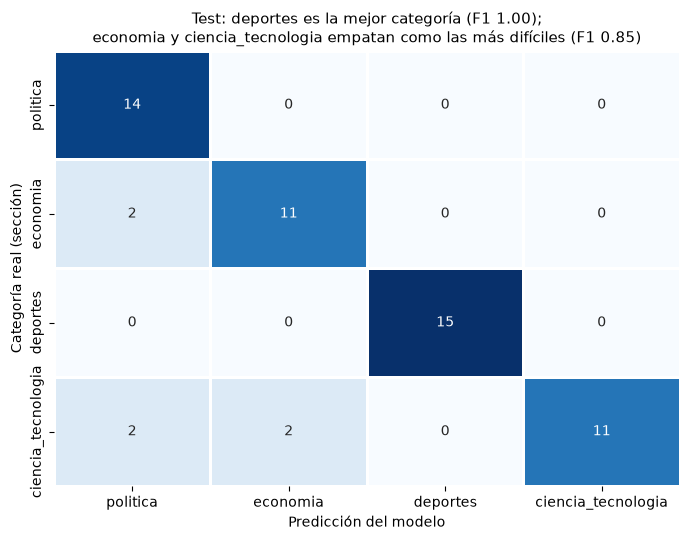

In [16]:
f1_cat = pd.Series(f1_score(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS, average=None,
                            zero_division=0), index=ETIQUETAS)
cm = confusion_matrix(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, ax=ax)
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Categoría real (sección)")
peores = f1_cat[np.isclose(f1_cat, f1_cat.min())].index.tolist()  # puede haber empate
ax.set_title(f"Test: {f1_cat.idxmax()} es la mejor categoría (F1 {f1_cat.max():.2f});\n"
             + (f"{' y '.join(peores)} empatan como las más difíciles" if len(peores) > 1
                else f"{peores[0]} es la más difícil") + f" (F1 {f1_cat.min():.2f})", fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
errores = test_df[test_df["pred_ft"] != test_df["etiqueta"]]
print(f"Errores en test: {len(errores)} de {len(test_df)}")
with pd.option_context("display.max_colwidth", None):
    display(errores[["titular", "etiqueta", "pred_ft", "seccion_original"]])

Errores en test: 6 de 57


,titular,etiqueta,pred_ft,seccion_original
261,Gobierno designa presidenta del directorio y directora ejecutiva del Fonafe,economia,politica,economia/peru
41,Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de la minería ilegal en Tambopata,ciencia_tecnologia,economia,tecnologia/ecologia
63,Trump llama a Musk un “tesoro nacional” tras condecorarlo con galardón científico de Estados Unidos,ciencia_tecnologia,politica,tecnologia/actualidad
262,Mincetur designa a Roxana Barrantes como nuevo miembro del Consejo Directivo de Indecopi,economia,politica,economia/peru
59,Informe Planeta Vivo 2026: la fauna silvestre cae 73% y América Latina es la región más golpeada (95 %),ciencia_tecnologia,economia,tecnologia/actualidad
60,Trump quiere llamar “superinteligencia” a la IA y amenaza con tratar como “enemigo” a quien no lo haga,ciencia_tecnologia,politica,tecnologia/actualidad


### Reflexión por categoría

- **Mejor: `deportes` (F1 1.00, 15 de 15 y ningún falso positivo).** Su vocabulario es el más exclusivo: nombres de clubes y atletas, *duelo*, *goles*, *torneo*, marcadores como *3-1*. Además, sus 98 notas se publicaron en solo 3 días (Parte 1), así que train y test comparten los mismos eventos (Caminos del Inca, el Torneo Clausura). Esto facilita la tarea, y es probable que el F1 perfecto esté algo inflado por ese sesgo temporal.
- **`politica` (F1 0.88): recupera todo (14 de 14) pero atrae 4 falsos positivos.** El modelo solo ve el titular, y en un titular los actores y los verbos de gobierno pesan más que el tema:
  - *"Gobierno designa… Fonafe"* y *"Mincetur designa… Indecopi"* son nombramientos que el diario publica en economía.
  - *Trump* aparece en dos notas de tecnología (Musk e inteligencia artificial).
- **Peores, empatadas: `economia` y `ciencia_tecnologia` (F1 0.85).**
  - **`economia`** pierde los dos nombramientos ya mencionados, que se van a política. Además recibe dos notas ambientales de tecnología: la minería ilegal en Madre de Dios y el informe Planeta Vivo, con su *"cae 73 %"*. La causa es lingüística: *minería*, los porcentajes y las cifras son vocabulario típico de economía.
  - **`ciencia_tecnologia`** tiene la menor cobertura (11 de 15), porque es la sección más heterogénea. Mezcla tecnología con ecología y medio ambiente, y con noticias de política tecnológica protagonizadas por políticos. Cuando el titular no menciona un producto o un término técnico, el modelo no tiene pistas propias de la categoría.
- **Comparación con el LLM:** el LLM acierta 3 de esas 4 notas de tecnología, porque lee también la bajada y tiene conocimiento del mundo (sabe que *superinteligencia* es un tema de IA). En cambio, falla igual que DistilBERT en los nombramientos de Fonafe e Indecopi, que también para la auditoría humana fueron casos dudosos entre política y economía.

Con 57 titulares de test, cada error mueve el F1 de una categoría entre 3 y 7 puntos. Por eso las diferencias entre las tres categorías no deportivas (0.85–0.88) equivalen a 1 o 2 noticias.